In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/pred_vs_actual.png
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/training_curves.png
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/y_train.npy
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/y_test.npy
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/y_val.npy
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/sunnet_best.keras
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/error_dist.png
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/X_test.npy
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/X_val.npy
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/X_train.npy
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs/sunnet_2dcnn_final.keras


In [2]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    print(root)
    for f in files:
        print('   ', f)   

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/eswarvardhankottana
/kaggle/input/datasets/eswarvardhankottana/sunnet-outputs
    pred_vs_actual.png
    training_curves.png
    y_train.npy
    y_test.npy
    y_val.npy
    sunnet_best.keras
    error_dist.png
    X_test.npy
    X_val.npy
    X_train.npy
    sunnet_2dcnn_final.keras


[STEP 1] Loading per-frame arrays...
  X_train: (83958, 64, 64, 3)   y range=[0.000,29.585]

[STEP 2] Rebuilding SunNET and loading weights...
  Encoder output: (4,4,256)

[STEP 3] Pre-extracting features...
164/164 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step
  feats_train: (83958, 4, 4, 256)  656 MB
  Raw images freed.

[STEP 4] Building subsampled sequence arrays (stride=4)...
  X_train_seq: (20988, 6, 4, 4, 256)  1968 MB
  X_val_seq  : (4496, 6, 4, 4, 256)  422 MB
  X_test_seq : (4496, 6, 4, 4, 256)  422 MB
  Feature arrays freed.

[STEP 5] Building ConvLSTM+LSTM model...


Model: "ConvLSTM_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ feat_seq_input (InputLayer)       │ (None, 6, 4, 4, 256)     │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ convlstm_1 (ConvLSTM2D)           │ (None, 6, 4, 4, 128)     │     1,769,984 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ bn_cl1 (BatchNormalization)       │ (None, 6, 4, 4, 128)     │           512 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ convlstm_2 (ConvLSTM2D)           │ (None, 6, 4, 4, 64)      │       442,624 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ bn_cl2 (BatchNormalization)       │ (None, 6, 4, 4, 64)      │           256 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ td_gap (TimeDistributed)          │ (None, 6, 64)            │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                     │ (None, 6, 128)           │        98,816 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ drop_l1 (Dropout)                 │ (None, 6, 128)           │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                     │ (None, 64)               │        49,408 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ drop_l2 (Dropout)                 │ (None, 64)               │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ head_dense (Dense)                │ (None, 64)               │         4,160 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ drop_head (Dropout)               │ (None, 64)               │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ pv_output (Dense)                 │ (None, 4)                │           260 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 2,366,020 (9.03 MB)

 Trainable params: 2,365,636 (9.02 MB)

 Non-trainable params: 384 (1.50 KB)

  Total params: 2,366,020

[STEP 6] Training... (20988 train sequences, batch=64, steps/epoch=327)
Epoch 1/80


E0000 00:00:1789325317.572616      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: MutableGraphView::SortTopologically error: detected edge(s) creating cycle(s) {'StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_2_1/while/StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_2_1/zeros_switch/_347-0-TransposeNHWCToNCHW-LayoutOptimizer' -> 'StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_2_1/while/StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_2_1/zeros_switch/_347', 'Func/StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_2_1/while/body/_264/input/_1109' -> 'StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_2_1/while/body/_264/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/mul', 'Func/StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_1_1/while/body/_81/input/_988' -> 'StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_1_1/while/body/_81/ConvLSTM_LSTM_1/convlstm_1_1/while/conv_lstm_cell_1/mul', 'StatefulPartitionedCall/ConvLSTM_LSTM_1/convlstm_1_1/while/StatefulPartitionedCall/Co

328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 6.4402 - mae: 6.8447
Epoch 1: val_loss improved from None to 0.60925, saving model to /kaggle/working/convlstm_lstm_best.keras

Epoch 1: finished saving model to /kaggle/working/convlstm_lstm_best.keras
328/328 ━━━━━━━━━━━━━━━━━━━━ 29s 67ms/step - loss: 3.3575 - mae: 3.7447 - val_loss: 0.6092 - val_mae: 0.9246 - learning_rate: 5.0000e-04
Epoch 2/80
328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.1813 - mae: 1.5477
Epoch 2: val_loss improved from 0.60925 to 0.51049, saving model to /kaggle/working/convlstm_lstm_best.keras

Epoch 2: finished saving model to /kaggle/working/convlstm_lstm_best.keras
328/328 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - loss: 1.1500 - mae: 1.5132 - val_loss: 0.5105 - val_mae: 0.8075 - learning_rate: 5.0000e-04
Epoch 3/80
328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.0451 - mae: 1.4041
Epoch 3: val_loss did not improve from 0.51049
328/328 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - loss: 1.0219 - mae: 1.3801 - val

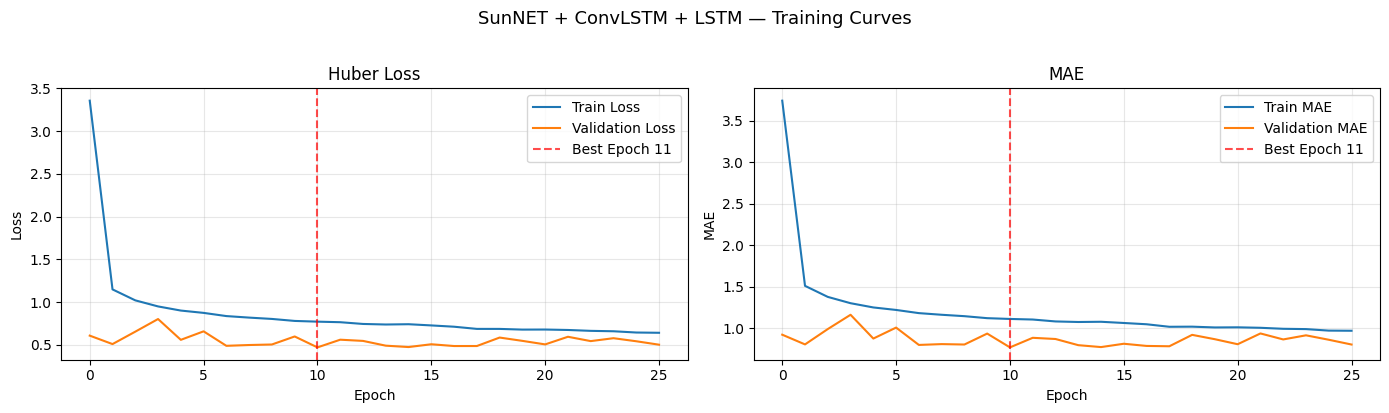

  Saved: pipeline_training_curves.png

[STEP 7] Evaluating on test set...
 4/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step  

E0000 00:00:1789325843.717275      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: MutableGraphView::SortTopologically error: detected edge(s) creating cycle(s) {'ConvLSTM_LSTM_1/convlstm_2_1/while/body/_44/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/mul' -> 'ConvLSTM_LSTM_1/convlstm_2_1/while/body/_44/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/add_7', 'ConvLSTM_LSTM_1/convlstm_2_1/while/body/_44/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/Tanh_1' -> 'ConvLSTM_LSTM_1/convlstm_2_1/while/body/_44/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/mul_2', 'ConvLSTM_LSTM_1/convlstm_2_1/while/body/_44/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/convolution_7' -> 'ConvLSTM_LSTM_1/convlstm_2_1/while/body/_44/ConvLSTM_LSTM_1/convlstm_2_1/while/conv_lstm_cell_1/ArithmeticOptimizer/AddOpsRewrite_Leaf_1_add_8', 'ConvLSTM_LSTM_1/convlstm_1_1/while/body/_1/ConvLSTM_LSTM_1/convlstm_1_1/while/conv_lstm_cell_1/mul' -> 'ConvLSTM_LSTM_1/convlstm_1_1/while/bod

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step

  SunNET + ConvLSTM + LSTM — TEST RESULTS
  t+1: MAE=1.1268  RMSE=1.5454  R²=0.9503  nRMSE=5.97%
  t+2: MAE=1.1678  RMSE=1.6315  R²=0.9445  nRMSE=6.43%
  t+3: MAE=1.1988  RMSE=1.6964  R²=0.9400  nRMSE=6.73%
  t+4: MAE=1.2306  RMSE=1.7580  R²=0.9357  nRMSE=6.76%
----------------------------------------------------------
  Overall: MAE=1.1810  RMSE=1.6597  R²=0.9426  nRMSE=6.38%
  nRMSE guide: <10% excellent | 10-20% good | >20% poor


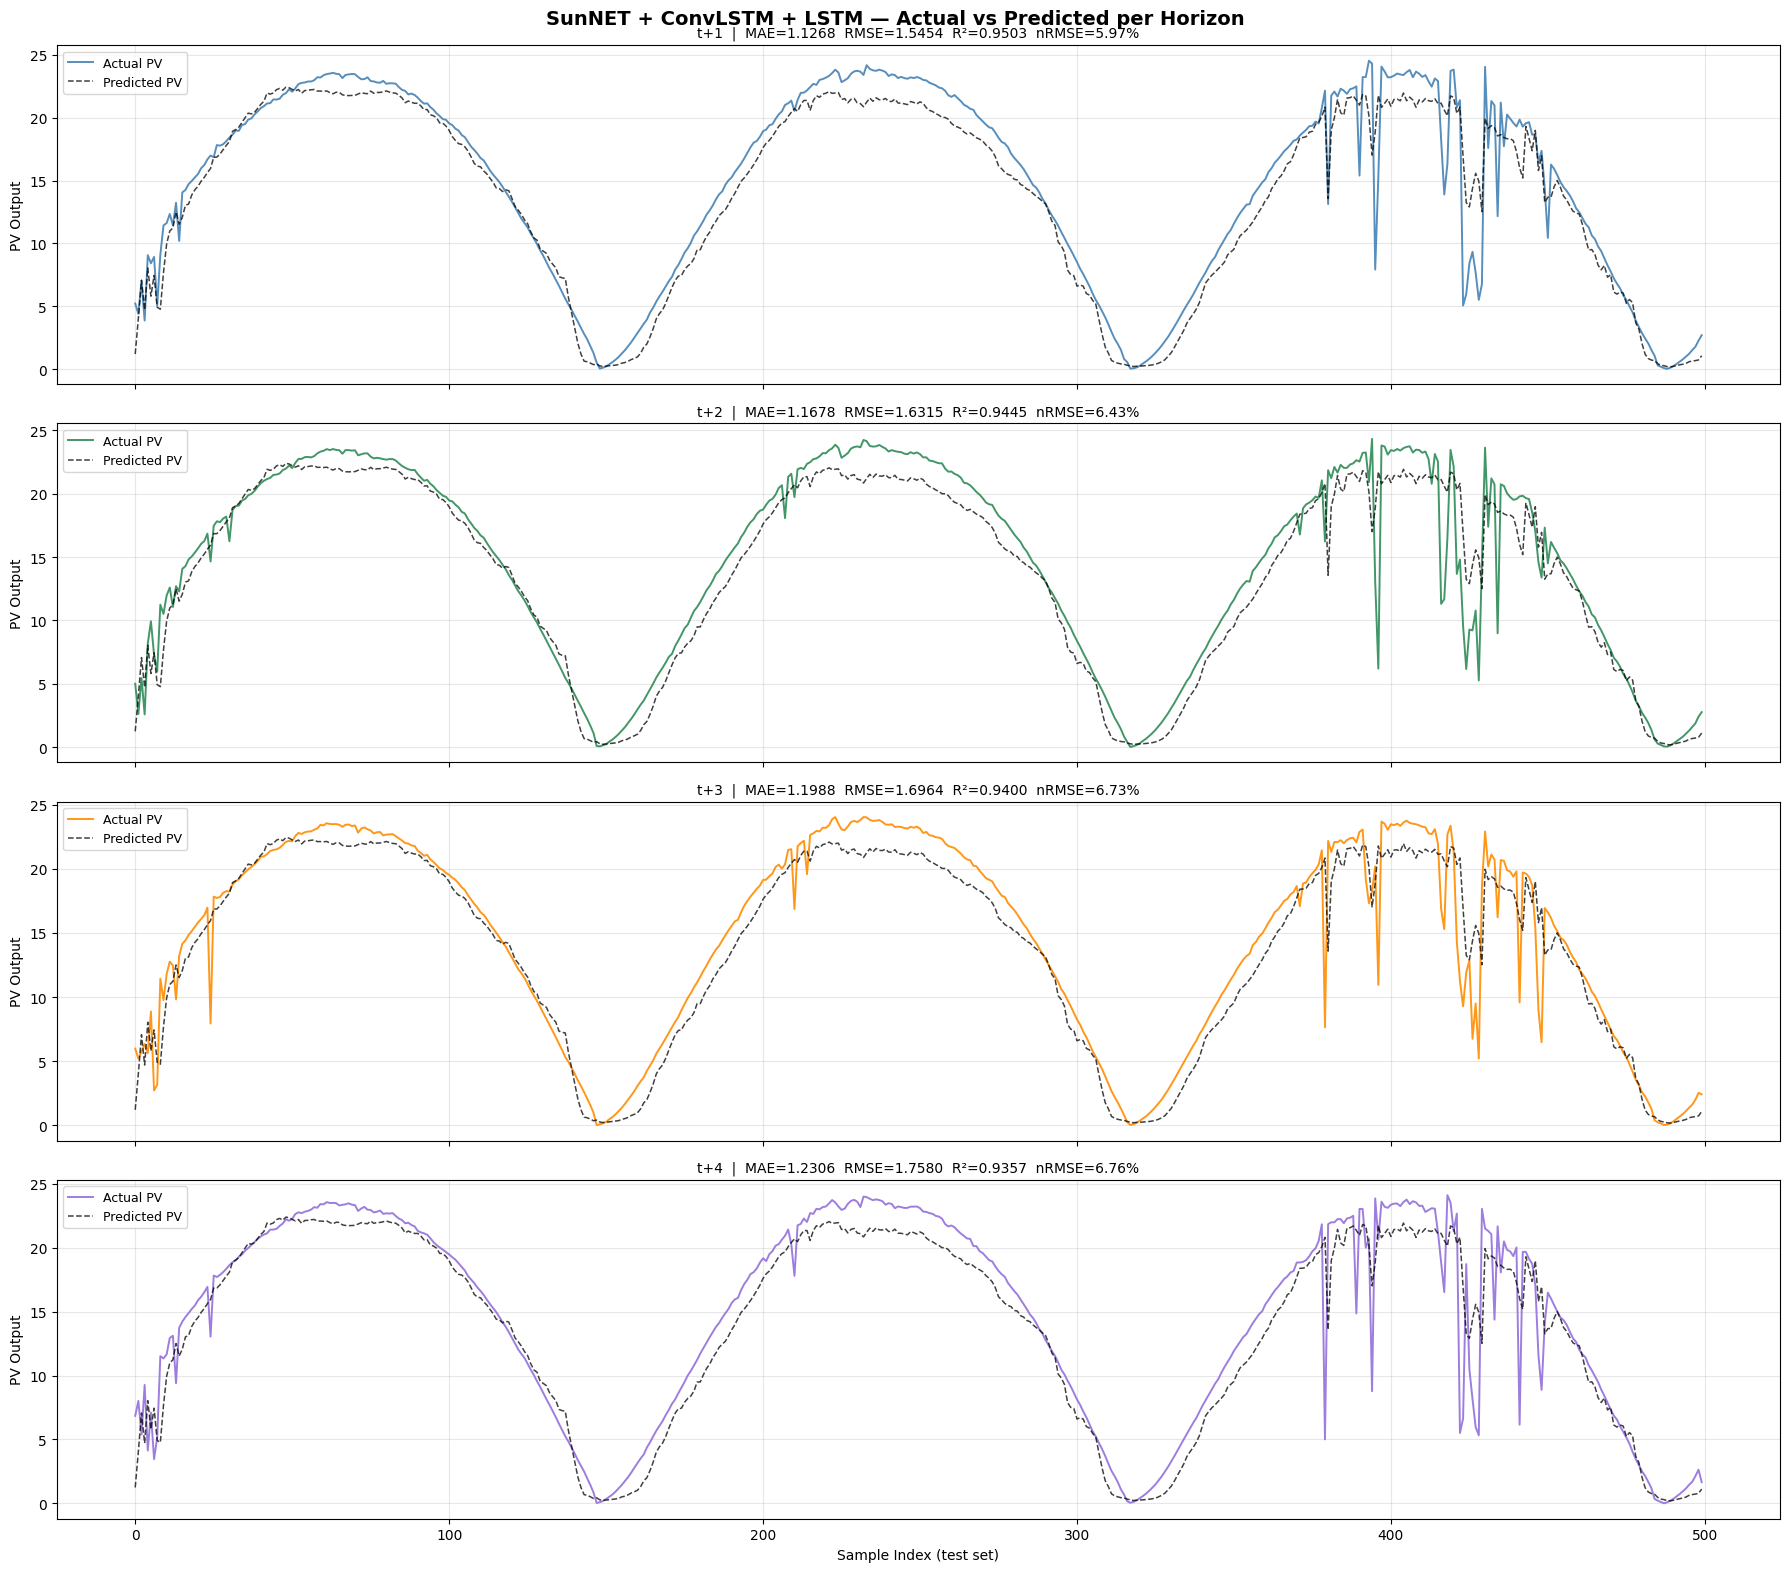

  Saved: actual_vs_predicted.png


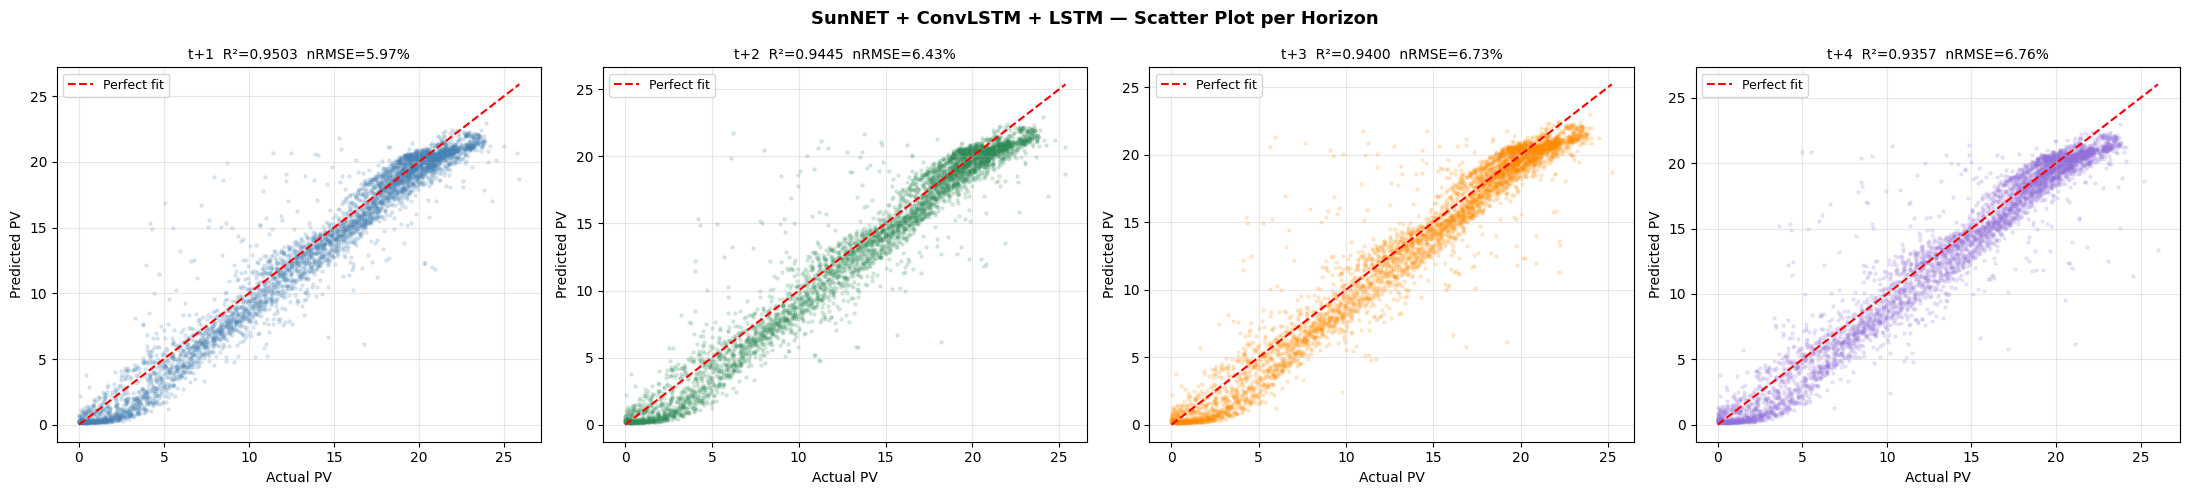

  Saved: scatter_per_horizon.png


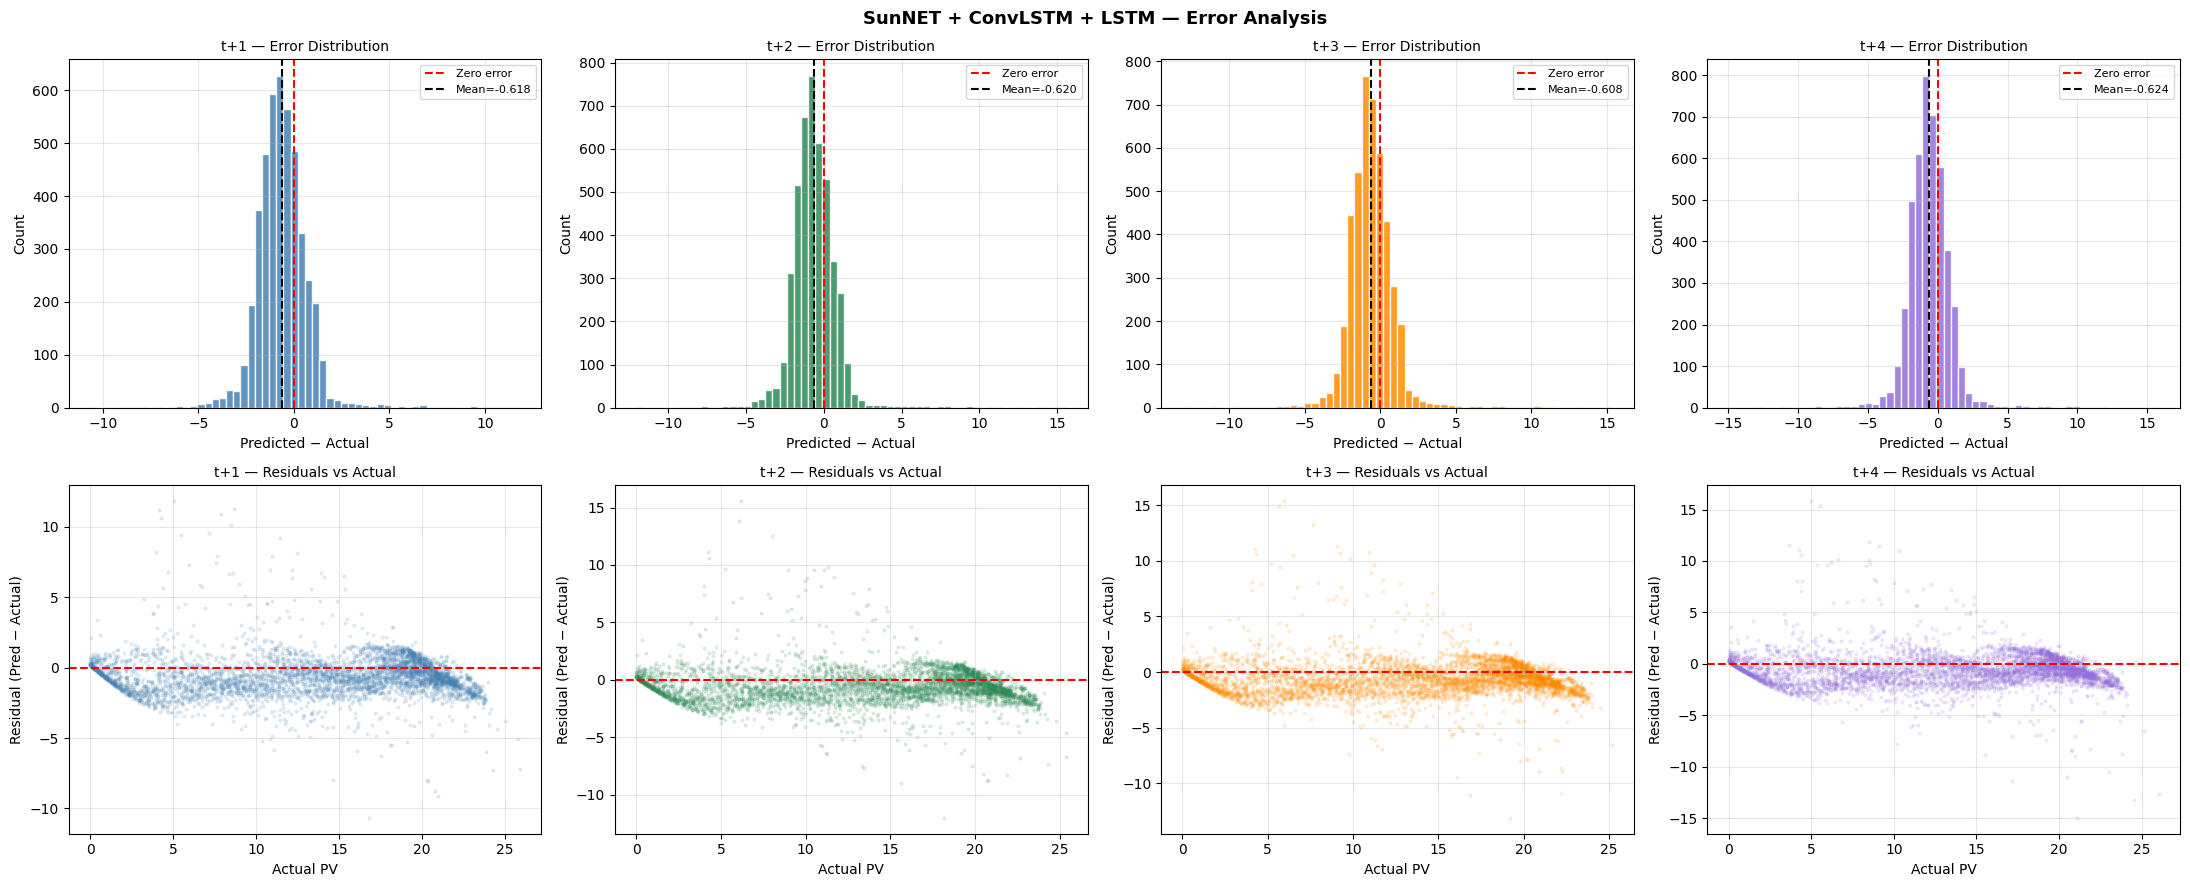

  Saved: error_analysis.png


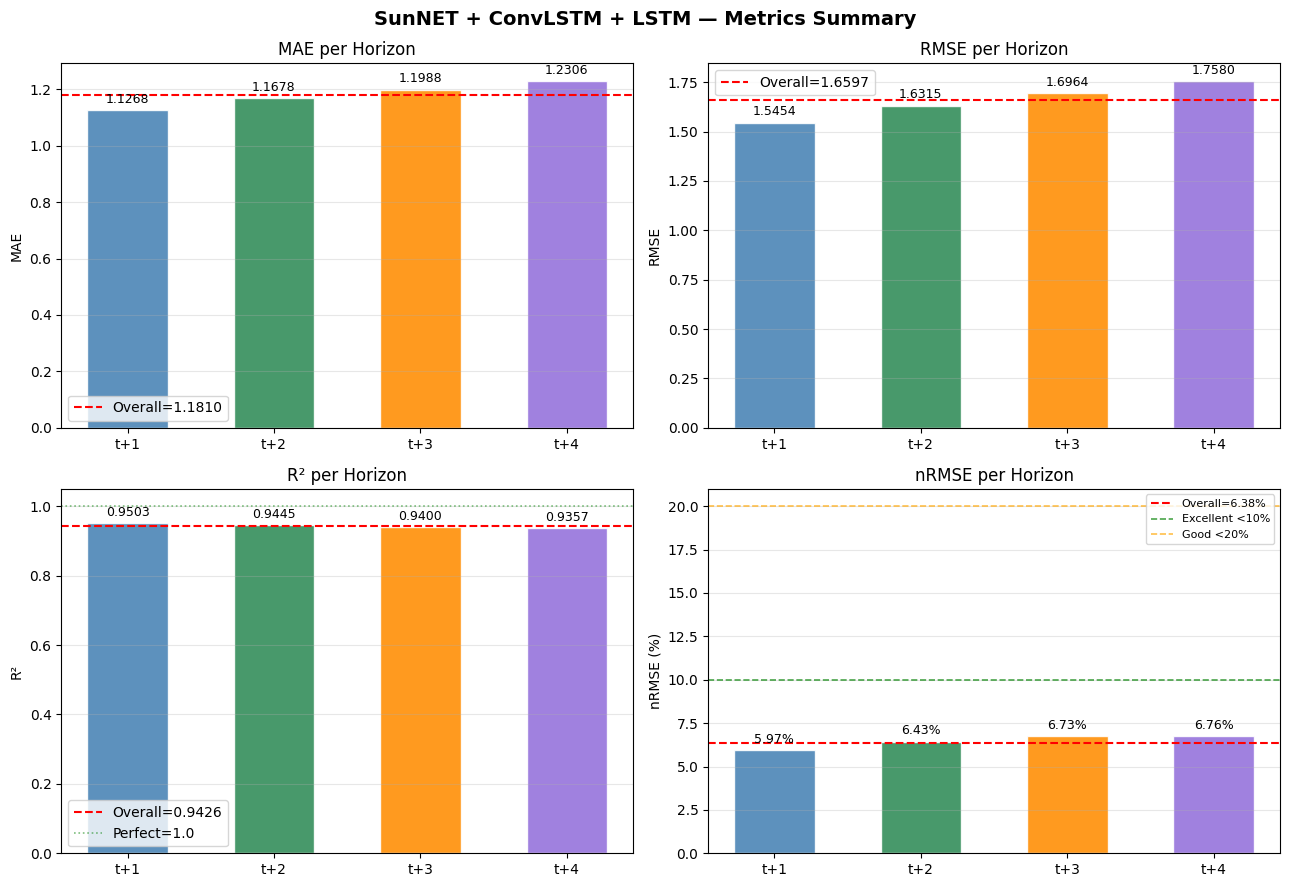

  Saved: metrics_summary.png

  Model saved → /kaggle/working/convlstm_lstm_final.keras

  OUTPUT FILES
  pipeline_training_curves.png  — loss + MAE curves
  actual_vs_predicted.png       — time series per horizon
  scatter_per_horizon.png       — scatter per horizon
  error_analysis.png            — error distribution + residuals
  metrics_summary.png           — MAE, RMSE, R², nRMSE
  convlstm_lstm_final.keras     — saved final model
[DONE]


In [2]:
# ============================================================
#  STAGE 2 — FINAL VERSION
#
#  Code 2 training pipeline
#  +
#  Complete evaluation and visualization from Code 1
#
#  Architecture:
#  SunNET Encoder
#       ↓
#  ConvLSTM(128)
#       ↓
#  BatchNorm
#       ↓
#  ConvLSTM(64)
#       ↓
#  BatchNorm
#       ↓
#  TimeDistributed(GlobalAveragePooling2D)
#       ↓
#  LSTM(128)
#       ↓
#  Dropout(0.30)
#       ↓
#  LSTM(64)
#       ↓
#  Dropout(0.20)
#       ↓
#  Dense(64)
#       ↓
#  Dropout(0.15)
#       ↓
#  Dense(4)
#
# ============================================================


# ============================================================
#  IMPORTS
# ============================================================

import numpy as np
import os
import gc

import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import matplotlib.pyplot as plt


# ============================================================
#  CONFIGURATION
# ============================================================

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

tf.keras.mixed_precision.set_global_policy("mixed_float16")


IMG_H = 64
IMG_W = 64
IMG_C = 3

SEQ_LEN = 6
N_HORIZON = 4

BATCH = 64

L2_REG = 1e-4
DROP = 0.3

STRIDE = 4

AUTOTUNE = tf.data.AUTOTUNE


INPUT_DIR = (
    '/kaggle/input/datasets/'
    'eswarvardhankottana/'
    'sunnet-outputs'
)

SUNNET_PATH = os.path.join(
    INPUT_DIR,
    'sunnet_2dcnn_final.keras'
)

CKPT_DIR = '/kaggle/working'


# ============================================================
#  SECTION 1 — LOAD DATA
# ============================================================

print("[STEP 1] Loading per-frame arrays...")


required_files = [

    'X_train.npy',
    'X_val.npy',
    'X_test.npy',

    'y_train.npy',
    'y_val.npy',
    'y_test.npy'
]


for f in required_files:

    path = os.path.join(INPUT_DIR, f)

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"Missing file: {path}"
        )


X_train = np.load(
    os.path.join(INPUT_DIR, 'X_train.npy')
)

X_val = np.load(
    os.path.join(INPUT_DIR, 'X_val.npy')
)

X_test = np.load(
    os.path.join(INPUT_DIR, 'X_test.npy')
)


y_train = np.load(
    os.path.join(INPUT_DIR, 'y_train.npy')
).astype(np.float32)


y_val = np.load(
    os.path.join(INPUT_DIR, 'y_val.npy')
).astype(np.float32)


y_test = np.load(
    os.path.join(INPUT_DIR, 'y_test.npy')
).astype(np.float32)


print(
    f"  X_train: {X_train.shape}   "
    f"y range=[{y_train.min():.3f},"
    f"{y_train.max():.3f}]"
)


# ============================================================
#  SECTION 2 — REBUILD SunNET + LOAD WEIGHTS
# ============================================================

print(
    "\n[STEP 2] Rebuilding SunNET and loading weights..."
)


# ------------------------------------------------------------
#  CONV + BATCHNORM + RELU
# ------------------------------------------------------------

def conv_bn_relu(
    x,
    filters,
    kernel=3,
    name=""
):

    x = layers.Conv2D(

        filters,

        kernel_size=kernel,

        padding="same",

        use_bias=False,

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name=f"{name}_conv"

    )(x)


    x = layers.BatchNormalization(

        name=f"{name}_bn"

    )(x)


    x = layers.Activation(

        "relu",

        name=f"{name}_relu"

    )(x)


    return x



# ------------------------------------------------------------
#  RESIDUAL BLOCK
# ------------------------------------------------------------

def res_block(
    x,
    filters,
    name="res"
):

    shortcut = x


    x = conv_bn_relu(

        x,

        filters,

        3,

        f"{name}_a"

    )


    x = layers.Conv2D(

        filters,

        3,

        padding="same",

        use_bias=False,

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name=f"{name}_b_conv"

    )(x)


    x = layers.BatchNormalization(

        name=f"{name}_b_bn"

    )(x)


    # Projection shortcut if channels differ
    if shortcut.shape[-1] != filters:

        shortcut = layers.Conv2D(

            filters,

            1,

            padding="same",

            use_bias=False,

            name=f"{name}_proj"

        )(shortcut)


        shortcut = layers.BatchNormalization(

            name=f"{name}_proj_bn"

        )(shortcut)


    x = layers.Add(

        name=f"{name}_add"

    )([x, shortcut])


    return layers.Activation(

        "relu",

        name=f"{name}_out"

    )(x)



# ------------------------------------------------------------
#  CHANNEL ATTENTION
# ------------------------------------------------------------

def channel_attention(
    x,
    ratio=8,
    name="ca"
):

    C = x.shape[-1]


    gap = layers.GlobalAveragePooling2D(

        name=f"{name}_gap"

    )(x)


    gmp = layers.GlobalMaxPooling2D(

        name=f"{name}_gmp"

    )(x)



    def excite(
        v,
        s
    ):

        v = layers.Dense(

            C // ratio,

            activation="relu",

            kernel_regularizer=
            regularizers.l2(L2_REG),

            name=f"{name}_fc1_{s}"

        )(v)


        return layers.Dense(

            C,

            name=f"{name}_fc2_{s}"

        )(v)



    att = layers.Add(

        name=f"{name}_sum"

    )([

        excite(gap, "gap"),

        excite(gmp, "gmp")

    ])


    att = layers.Activation(

        "sigmoid",

        name=f"{name}_sig"

    )(att)


    att = layers.Reshape(

        (1, 1, C),

        name=f"{name}_rs"

    )(att)


    return layers.Multiply(

        name=f"{name}_out"

    )([

        x,

        att

    ])



# ------------------------------------------------------------
#  SPATIAL ATTENTION
# ------------------------------------------------------------

def spatial_attention(
    x,
    name="sa"
):

    avg_f = layers.Lambda(

        lambda t:
        tf.reduce_mean(
            t,
            axis=-1,
            keepdims=True
        ),

        output_shape=
        lambda s: s[:-1] + (1,),

        name=f"{name}_avg"

    )(x)


    max_f = layers.Lambda(

        lambda t:
        tf.reduce_max(
            t,
            axis=-1,
            keepdims=True
        ),

        output_shape=
        lambda s: s[:-1] + (1,),

        name=f"{name}_max"

    )(x)


    cat = layers.Concatenate(

        axis=-1,

        name=f"{name}_cat"

    )([

        avg_f,

        max_f

    ])


    att = layers.Conv2D(

        1,

        7,

        padding="same",

        use_bias=False,

        name=f"{name}_conv"

    )(cat)


    att = layers.Activation(

        "sigmoid",

        name=f"{name}_sig"

    )(att)


    return layers.Multiply(

        name=f"{name}_out"

    )([

        x,

        att

    ])



# ------------------------------------------------------------
#  BUILD SunNET
# ------------------------------------------------------------

def build_sunnet():

    inp = layers.Input(

        shape=(

            IMG_H,

            IMG_W,

            IMG_C

        ),

        name="image_input"

    )


    # Block 1
    x = res_block(

        inp,

        32,

        name="b1"

    )


    x = layers.MaxPooling2D(

        2,

        name="pool1"

    )(x)


    x = layers.SpatialDropout2D(

        0.10,

        name="sdrop1"

    )(x)



    # Block 2
    x = res_block(

        x,

        64,

        name="b2"

    )


    x = layers.MaxPooling2D(

        2,

        name="pool2"

    )(x)


    x = layers.SpatialDropout2D(

        0.10,

        name="sdrop2"

    )(x)



    # Block 3
    x = res_block(

        x,

        128,

        name="b3"

    )


    x = layers.MaxPooling2D(

        2,

        name="pool3"

    )(x)


    x = layers.SpatialDropout2D(

        0.15,

        name="sdrop3"

    )(x)



    # Block 4
    x = res_block(

        x,

        256,

        name="b4"

    )


    x = layers.MaxPooling2D(

        2,

        name="pool4"

    )(x)



    # Attention
    x = channel_attention(

        x,

        ratio=8,

        name="ca"

    )


    x = spatial_attention(

        x,

        name="sa"

    )



    # Global pooling
    gap = layers.GlobalAveragePooling2D(

        name="gap"

    )(x)


    gmp = layers.GlobalMaxPooling2D(

        name="gmp"

    )(x)


    x = layers.Concatenate(

        name="pool_concat"

    )([

        gap,

        gmp

    ])



    # Dense head
    x = layers.Dense(

        256,

        activation="relu",

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name="dense1"

    )(x)


    x = layers.BatchNormalization(

        name="head_bn1"

    )(x)


    x = layers.Dropout(

        DROP,

        name="drop1"

    )(x)



    x = layers.Dense(

        128,

        activation="relu",

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name="dense2"

    )(x)


    x = layers.BatchNormalization(

        name="head_bn2"

    )(x)


    x = layers.Dropout(

        DROP * 0.6,

        name="drop2"

    )(x)



    x = layers.Dense(

        64,

        activation="relu",

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name="dense3"

    )(x)


    x = layers.Dropout(

        0.1,

        name="drop3"

    )(x)



    out = layers.Dense(

        1,

        activation="linear",

        dtype="float32",

        name="pv_output"

    )(x)



    return models.Model(

        inputs=inp,

        outputs=out,

        name="SunNET_2DCNN"

    )



# ============================================================
#  LOAD SunNET WEIGHTS
# ============================================================

sunnet_full = build_sunnet()


sunnet_full.load_weights(

    SUNNET_PATH

)


# Extract spatial features from sa_out
encoder = models.Model(

    inputs=sunnet_full.input,

    outputs=
    sunnet_full.get_layer(
        "sa_out"
    ).output,

    name="SunNET_encoder"

)


FEAT_H, FEAT_W, FEAT_C = (
    encoder.output_shape[1:]
)


print(

    f"  Encoder output: "
    f"({FEAT_H},{FEAT_W},{FEAT_C})"

)



# ============================================================
#  SECTION 3 — PRE-EXTRACT FEATURES
# ============================================================

print(
    "\n[STEP 3] Pre-extracting features..."
)



def extract_features(
    X,
    batch_size=512
):

    ds = (

        tf.data.Dataset
        .from_tensor_slices(X)

        .map(

            lambda x:
            tf.cast(
                x,
                tf.float32
            ) / 255.0,

            num_parallel_calls=
            AUTOTUNE

        )

        .batch(batch_size)

        .prefetch(AUTOTUNE)

    )


    return encoder.predict(

        ds,

        verbose=1

    ).astype(
        np.float16
    )



feats_train = extract_features(

    X_train

)


feats_val = extract_features(

    X_val

)


feats_test = extract_features(

    X_test

)



print(

    f"  feats_train: "
    f"{feats_train.shape}  "

    f"{feats_train.nbytes / 1024**2:.0f} MB"

)



# Free raw image memory
del X_train
del X_val
del X_test
del sunnet_full

gc.collect()


print(
    "  Raw images freed."
)



# ============================================================
#  SECTION 4 — BUILD SUBSAMPLED SEQUENCES
# ============================================================

print(

    f"\n[STEP 4] Building "
    f"subsampled sequence arrays "
    f"(stride={STRIDE})..."

)



def build_seq_strided(

    feats,

    y,

    seq_len=SEQ_LEN,

    horizon=N_HORIZON,

    stride=STRIDE

):

    n = len(feats)


    max_start = (

        n
        - seq_len
        - horizon

    )


    starts = np.arange(

        0,

        max_start + 1,

        stride,

        dtype=np.int32

    )


    # Shape:
    # (N_sequences, seq_len)

    col_idx = (

        starts[:, None]

        +

        np.arange(seq_len)

    )


    # Input sequences
    X_seq = feats[
        col_idx
    ].astype(
        np.float32
    )


    # Multi-horizon output
    y_seq = np.array(

        [

            y[
                s + seq_len:
                s + seq_len + horizon
            ]

            for s in starts

        ],

        dtype=np.float32

    )


    return X_seq, y_seq



X_tr, y_tr = build_seq_strided(

    feats_train,

    y_train

)


X_va, y_va = build_seq_strided(

    feats_val,

    y_val

)


X_te, y_te = build_seq_strided(

    feats_test,

    y_test

)



print(

    f"  X_train_seq: "
    f"{X_tr.shape}  "

    f"{X_tr.nbytes / 1024**2:.0f} MB"

)


print(

    f"  X_val_seq  : "
    f"{X_va.shape}  "

    f"{X_va.nbytes / 1024**2:.0f} MB"

)


print(

    f"  X_test_seq : "
    f"{X_te.shape}  "

    f"{X_te.nbytes / 1024**2:.0f} MB"

)



# Free extracted features
del feats_train
del feats_val
del feats_test

gc.collect()


print(
    "  Feature arrays freed."
)



# ============================================================
#  SECTION 5 — ConvLSTM + LSTM MODEL
# ============================================================

print(

    "\n[STEP 5] Building ConvLSTM+LSTM model..."

)



def build_model(

    seq_len=SEQ_LEN,

    feat_shape=(
        FEAT_H,
        FEAT_W,
        FEAT_C
    ),

    n_horizon=N_HORIZON

):


    # --------------------------------------------------------
    # INPUT
    # --------------------------------------------------------

    inp = layers.Input(

        shape=(

            seq_len,

        ) + feat_shape,

        name="feat_seq_input"

    )



    # --------------------------------------------------------
    # ConvLSTM 1
    # --------------------------------------------------------

    x = layers.ConvLSTM2D(

        128,

        3,

        padding="same",

        return_sequences=True,

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name="convlstm_1"

    )(inp)


    x = layers.BatchNormalization(

        name="bn_cl1"

    )(x)



    # --------------------------------------------------------
    # ConvLSTM 2
    # --------------------------------------------------------

    x = layers.ConvLSTM2D(

        64,

        3,

        padding="same",

        return_sequences=True,

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name="convlstm_2"

    )(x)


    x = layers.BatchNormalization(

        name="bn_cl2"

    )(x)



    # --------------------------------------------------------
    # GLOBAL SPATIAL POOLING
    # --------------------------------------------------------

    x = layers.TimeDistributed(

        layers.GlobalAveragePooling2D(),

        name="td_gap"

    )(x)



    # --------------------------------------------------------
    # LSTM 1
    # --------------------------------------------------------

    x = layers.LSTM(

        128,

        return_sequences=True,

        name="lstm_1"

    )(x)


    x = layers.Dropout(

        0.30,

        name="drop_l1"

    )(x)



    # --------------------------------------------------------
    # LSTM 2
    # --------------------------------------------------------

    x = layers.LSTM(

        64,

        return_sequences=False,

        name="lstm_2"

    )(x)


    x = layers.Dropout(

        0.20,

        name="drop_l2"

    )(x)



    # --------------------------------------------------------
    # DENSE HEAD
    # --------------------------------------------------------

    x = layers.Dense(

        64,

        activation="relu",

        kernel_regularizer=
        regularizers.l2(L2_REG),

        name="head_dense"

    )(x)


    x = layers.Dropout(

        0.15,

        name="drop_head"

    )(x)



    # --------------------------------------------------------
    # MULTI-HORIZON OUTPUT
    # --------------------------------------------------------

    out = layers.Dense(

        n_horizon,

        activation="linear",

        dtype="float32",

        name="pv_output"

    )(x)



    return models.Model(

        inputs=inp,

        outputs=out,

        name="ConvLSTM_LSTM"

    )



model = build_model()


model.summary(
    line_length=80
)


print(

    f"  Total params: "
    f"{model.count_params():,}"

)



# ============================================================
#  SECTION 6 — TRAIN
# ============================================================

CKPT_BEST = os.path.join(

    CKPT_DIR,

    'convlstm_lstm_best.keras'

)



model.compile(

    optimizer=
    tf.keras.optimizers.Adam(

        learning_rate=5e-4,

        clipnorm=1.0

    ),

    loss=
    tf.keras.losses.Huber(

        delta=1.0

    ),

    metrics=[
        "mae"
    ]

)



callbacks = [


    EarlyStopping(

        monitor='val_loss',

        patience=15,

        restore_best_weights=True,

        verbose=1

    ),


    ModelCheckpoint(

        CKPT_BEST,

        monitor='val_loss',

        save_best_only=True,

        verbose=1

    ),


    ReduceLROnPlateau(

        monitor='val_loss',

        factor=0.5,

        patience=6,

        min_lr=1e-7,

        verbose=1

    )

]



print(

    f"\n[STEP 6] Training... "

    f"({len(X_tr)} train sequences, "

    f"batch={BATCH}, "

    f"steps/epoch={len(X_tr)//BATCH})"

)



history = model.fit(

    X_tr,

    y_tr,

    validation_data=(

        X_va,

        y_va

    ),

    batch_size=BATCH,

    epochs=80,

    callbacks=callbacks,

    verbose=1

)



best_ep = (

    int(
        np.argmin(
            history.history['val_loss']
        )
    )

    + 1

)



print(

    f"\n  Best epoch    : "
    f"{best_ep}"

)


print(

    f"  Best val_loss : "

    f"{min(history.history['val_loss']):.6f}"

)


print(

    f"  Best val_mae  : "

    f"{min(history.history['val_mae']):.6f}"

)



# ============================================================
#  SECTION 7 — TRAINING CURVES
# ============================================================

fig, axes = plt.subplots(

    1,

    2,

    figsize=(14, 4)

)



# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

axes[0].plot(

    history.history['loss'],

    label='Train Loss',

    lw=1.5

)


axes[0].plot(

    history.history['val_loss'],

    label='Validation Loss',

    lw=1.5

)


axes[0].axvline(

    best_ep - 1,

    color='red',

    ls='--',

    alpha=0.7,

    label=f'Best Epoch {best_ep}'

)


axes[0].set_title(

    'Huber Loss'

)


axes[0].set_xlabel(

    'Epoch'

)


axes[0].set_ylabel(

    'Loss'

)


axes[0].legend()

axes[0].grid(
    alpha=0.3
)



# ------------------------------------------------------------
# MAE
# ------------------------------------------------------------

axes[1].plot(

    history.history['mae'],

    label='Train MAE',

    lw=1.5

)


axes[1].plot(

    history.history['val_mae'],

    label='Validation MAE',

    lw=1.5

)


axes[1].axvline(

    best_ep - 1,

    color='red',

    ls='--',

    alpha=0.7,

    label=f'Best Epoch {best_ep}'

)


axes[1].set_title(

    'MAE'

)


axes[1].set_xlabel(

    'Epoch'

)


axes[1].set_ylabel(

    'MAE'

)


axes[1].legend()

axes[1].grid(
    alpha=0.3
)



plt.suptitle(

    'SunNET + ConvLSTM + LSTM — Training Curves',

    fontsize=13,

    y=1.02

)


plt.tight_layout()


plt.savefig(

    '/kaggle/working/'
    'pipeline_training_curves.png',

    dpi=150,

    bbox_inches='tight'

)


plt.show()


print(
    "  Saved: pipeline_training_curves.png"
)



# ============================================================
#  SECTION 8 — PREDICT
# ============================================================

print(

    "\n[STEP 7] Evaluating on test set..."

)


preds = model.predict(

    X_te,

    batch_size=BATCH,

    verbose=1

)



n = min(

    len(preds),

    len(y_te)

)



preds = preds[:n]

y_true = y_te[:n]



# ============================================================
#  COMPUTE PER-HORIZON METRICS
# ============================================================

mae_list = []

rmse_list = []

r2_list = []

nrmse_list = []



for h in range(N_HORIZON):


    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae_h = mean_absolute_error(

        y_true[:, h],

        preds[:, h]

    )



    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse_h = np.sqrt(

        mean_squared_error(

            y_true[:, h],

            preds[:, h]

        )

    )



    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    ss_res = np.sum(

        (

            y_true[:, h]

            -

            preds[:, h]

        ) ** 2

    )


    ss_tot = np.sum(

        (

            y_true[:, h]

            -

            y_true[:, h].mean()

        ) ** 2

    )


    r2_h = (

        1.0

        -

        ss_res / (

            ss_tot + 1e-8

        )

    )



    # --------------------------------------------------------
    # NORMALIZED RMSE
    # --------------------------------------------------------

    nrmse_h = (

        rmse_h

        /

        (

            y_true[:, h].max()

            -

            y_true[:, h].min()

            +

            1e-8

        )

    ) * 100



    # Store metrics
    mae_list.append(
        mae_h
    )


    rmse_list.append(
        rmse_h
    )


    r2_list.append(
        r2_h
    )


    nrmse_list.append(
        nrmse_h
    )



# ============================================================
#  OVERALL METRICS
# ============================================================

y_flat = y_true.flatten()

p_flat = preds.flatten()



ov_mae = mean_absolute_error(

    y_flat,

    p_flat

)


ov_rmse = np.sqrt(

    mean_squared_error(

        y_flat,

        p_flat

    )

)



ss_res_ov = np.sum(

    (

        y_flat

        -

        p_flat

    ) ** 2

)


ss_tot_ov = np.sum(

    (

        y_flat

        -

        y_flat.mean()

    ) ** 2

)



ov_r2 = (

    1.0

    -

    ss_res_ov

    /

    (

        ss_tot_ov

        +

        1e-8

    )

)



ov_nrmse = (

    ov_rmse

    /

    (

        y_flat.max()

        -

        y_flat.min()

        +

        1e-8

    )

) * 100



# ============================================================
#  PRINT RESULTS
# ============================================================

print(

    "\n"

    +

    "=" * 58

)


print(

    "  SunNET + ConvLSTM + LSTM — TEST RESULTS"

)


print(

    "=" * 58

)



for h in range(N_HORIZON):


    print(

        f"  t+{h+1}: "

        f"MAE={mae_list[h]:.4f}  "

        f"RMSE={rmse_list[h]:.4f}  "

        f"R²={r2_list[h]:.4f}  "

        f"nRMSE={nrmse_list[h]:.2f}%"

    )



print(

    "-" * 58

)


print(

    f"  Overall: "

    f"MAE={ov_mae:.4f}  "

    f"RMSE={ov_rmse:.4f}  "

    f"R²={ov_r2:.4f}  "

    f"nRMSE={ov_nrmse:.2f}%"

)


print(

    "=" * 58

)


print(

    "  nRMSE guide: "

    "<10% excellent | "

    "10-20% good | "

    ">20% poor"

)



# ============================================================
#  PLOT COLORS
# ============================================================

colors = [

    'steelblue',

    'seagreen',

    'darkorange',

    'mediumpurple'

]



# ============================================================
#  PLOT 1
#  ACTUAL vs PREDICTED TIME SERIES
# ============================================================

N_PLOT = min(

    500,

    n

)



fig, axes = plt.subplots(

    N_HORIZON,

    1,

    figsize=(

        18,

        4 * N_HORIZON

    ),

    sharex=True

)



fig.suptitle(

    'SunNET + ConvLSTM + LSTM — '
    'Actual vs Predicted per Horizon',

    fontsize=14,

    fontweight='bold'

)



for h in range(N_HORIZON):


    ax = axes[h]


    # Actual PV
    ax.plot(

        y_true[
            :N_PLOT,
            h
        ],

        color=colors[h],

        lw=1.4,

        alpha=0.9,

        label='Actual PV'

    )


    # Predicted PV
    ax.plot(

        preds[
            :N_PLOT,
            h
        ],

        color='black',

        lw=1.1,

        alpha=0.75,

        ls='--',

        label='Predicted PV'

    )


    ax.set_title(

        f't+{h+1}  |  '

        f'MAE={mae_list[h]:.4f}  '

        f'RMSE={rmse_list[h]:.4f}  '

        f'R²={r2_list[h]:.4f}  '

        f'nRMSE={nrmse_list[h]:.2f}%',

        fontsize=10

    )


    ax.set_ylabel(

        'PV Output'

    )


    ax.legend(

        loc='upper left',

        fontsize=9

    )


    ax.grid(
        alpha=0.3
    )



axes[-1].set_xlabel(

    'Sample Index (test set)'

)


plt.tight_layout()


plt.savefig(

    '/kaggle/working/'
    'actual_vs_predicted.png',

    dpi=150,

    bbox_inches='tight'

)


plt.show()


print(
    "  Saved: actual_vs_predicted.png"
)



# ============================================================
#  PLOT 2
#  SCATTER PLOT PER HORIZON
# ============================================================

fig, axes = plt.subplots(

    1,

    N_HORIZON,

    figsize=(

        5.5 * N_HORIZON,

        5

    )

)



fig.suptitle(

    'SunNET + ConvLSTM + LSTM — '
    'Scatter Plot per Horizon',

    fontsize=13,

    fontweight='bold'

)



for h in range(N_HORIZON):


    ax = axes[h]


    mn = min(

        y_true[:, h].min(),

        preds[:, h].min()

    )


    mx = max(

        y_true[:, h].max(),

        preds[:, h].max()

    )



    ax.scatter(

        y_true[:, h],

        preds[:, h],

        alpha=0.15,

        s=5,

        color=colors[h],

        rasterized=True

    )


    ax.plot(

        [mn, mx],

        [mn, mx],

        'r--',

        lw=1.5,

        label='Perfect fit'

    )


    ax.set_title(

        f't+{h+1}  '

        f'R²={r2_list[h]:.4f}  '

        f'nRMSE={nrmse_list[h]:.2f}%',

        fontsize=10

    )


    ax.set_xlabel(

        'Actual PV'

    )


    ax.set_ylabel(

        'Predicted PV'

    )


    ax.legend(
        fontsize=9
    )


    ax.grid(
        alpha=0.3
    )



plt.tight_layout()


plt.savefig(

    '/kaggle/working/'
    'scatter_per_horizon.png',

    dpi=150,

    bbox_inches='tight'

)


plt.show()


print(
    "  Saved: scatter_per_horizon.png"
)



# ============================================================
#  PLOT 3
#  ERROR ANALYSIS
#
#  Top row:
#      Error distribution
#
#  Bottom row:
#      Residual vs Actual
# ============================================================

fig, axes = plt.subplots(

    2,

    N_HORIZON,

    figsize=(

        5.5 * N_HORIZON,

        9

    )

)



fig.suptitle(

    'SunNET + ConvLSTM + LSTM — '
    'Error Analysis',

    fontsize=13,

    fontweight='bold'

)



for h in range(N_HORIZON):


    errors = (

        preds[:, h]

        -

        y_true[:, h]

    )



    # --------------------------------------------------------
    # ERROR DISTRIBUTION
    # --------------------------------------------------------

    ax = axes[0, h]


    ax.hist(

        errors,

        bins=60,

        color=colors[h],

        edgecolor='white',

        alpha=0.85

    )


    ax.axvline(

        0,

        color='red',

        ls='--',

        lw=1.5,

        label='Zero error'

    )


    ax.axvline(

        errors.mean(),

        color='black',

        ls='--',

        lw=1.5,

        label=
        f'Mean={errors.mean():.3f}'

    )


    ax.set_title(

        f't+{h+1} — Error Distribution',

        fontsize=10

    )


    ax.set_xlabel(

        'Predicted − Actual'

    )


    ax.set_ylabel(

        'Count'

    )


    ax.legend(
        fontsize=8
    )


    ax.grid(
        alpha=0.3
    )



    # --------------------------------------------------------
    # RESIDUAL vs ACTUAL
    # --------------------------------------------------------

    ax = axes[1, h]


    ax.scatter(

        y_true[:, h],

        errors,

        alpha=0.12,

        s=4,

        color=colors[h],

        rasterized=True

    )


    ax.axhline(

        0,

        color='red',

        ls='--',

        lw=1.5

    )


    ax.set_title(

        f't+{h+1} — Residuals vs Actual',

        fontsize=10

    )


    ax.set_xlabel(

        'Actual PV'

    )


    ax.set_ylabel(

        'Residual '
        '(Pred − Actual)'

    )


    ax.grid(
        alpha=0.3
    )



plt.tight_layout()


plt.savefig(

    '/kaggle/working/'
    'error_analysis.png',

    dpi=150,

    bbox_inches='tight'

)


plt.show()


print(
    "  Saved: error_analysis.png"
)



# ============================================================
#  PLOT 4
#  METRICS SUMMARY
#
#  MAE
#  RMSE
#  R²
#  nRMSE
# ============================================================

horizons = [

    f't+{h+1}'

    for h in range(N_HORIZON)

]


x = np.arange(

    N_HORIZON

)


bar_w = 0.55



fig, axes = plt.subplots(

    2,

    2,

    figsize=(13, 9)

)



fig.suptitle(

    'SunNET + ConvLSTM + LSTM — '
    'Metrics Summary',

    fontsize=14,

    fontweight='bold'

)



# ============================================================
#  MAE
# ============================================================

ax = axes[0, 0]


bars = ax.bar(

    x,

    mae_list,

    bar_w,

    color=colors,

    edgecolor='white',

    alpha=0.88

)


ax.axhline(

    ov_mae,

    color='red',

    ls='--',

    lw=1.5,

    label=
    f'Overall={ov_mae:.4f}'

)


ax.bar_label(

    bars,

    fmt='%.4f',

    fontsize=9,

    padding=3

)


ax.set_title(

    'MAE per Horizon'

)


ax.set_xticks(x)

ax.set_xticklabels(
    horizons
)


ax.set_ylabel(
    'MAE'
)


ax.legend()

ax.grid(

    axis='y',

    alpha=0.3

)



# ============================================================
#  RMSE
# ============================================================

ax = axes[0, 1]


bars = ax.bar(

    x,

    rmse_list,

    bar_w,

    color=colors,

    edgecolor='white',

    alpha=0.88

)


ax.axhline(

    ov_rmse,

    color='red',

    ls='--',

    lw=1.5,

    label=
    f'Overall={ov_rmse:.4f}'

)


ax.bar_label(

    bars,

    fmt='%.4f',

    fontsize=9,

    padding=3

)


ax.set_title(

    'RMSE per Horizon'

)


ax.set_xticks(x)

ax.set_xticklabels(
    horizons
)


ax.set_ylabel(
    'RMSE'
)


ax.legend()

ax.grid(

    axis='y',

    alpha=0.3

)



# ============================================================
#  R²
# ============================================================

ax = axes[1, 0]


bars = ax.bar(

    x,

    r2_list,

    bar_w,

    color=colors,

    edgecolor='white',

    alpha=0.88

)


ax.axhline(

    ov_r2,

    color='red',

    ls='--',

    lw=1.5,

    label=
    f'Overall={ov_r2:.4f}'

)


ax.axhline(

    1.0,

    color='green',

    ls=':',

    lw=1.2,

    alpha=0.5,

    label='Perfect=1.0'

)


ax.bar_label(

    bars,

    fmt='%.4f',

    fontsize=9,

    padding=3

)


ax.set_title(

    'R² per Horizon'

)


ax.set_xticks(x)

ax.set_xticklabels(
    horizons
)


ax.set_ylabel(
    'R²'
)


ax.set_ylim(
    0,
    1.05
)


ax.legend()

ax.grid(

    axis='y',

    alpha=0.3

)



# ============================================================
#  nRMSE
# ============================================================

ax = axes[1, 1]


bars = ax.bar(

    x,

    nrmse_list,

    bar_w,

    color=colors,

    edgecolor='white',

    alpha=0.88

)


ax.axhline(

    ov_nrmse,

    color='red',

    ls='--',

    lw=1.5,

    label=
    f'Overall={ov_nrmse:.2f}%'

)


ax.axhline(

    10.0,

    color='green',

    ls='--',

    lw=1.2,

    alpha=0.7,

    label='Excellent <10%'

)


ax.axhline(

    20.0,

    color='orange',

    ls='--',

    lw=1.2,

    alpha=0.7,

    label='Good <20%'

)


ax.bar_label(

    bars,

    fmt='%.2f%%',

    fontsize=9,

    padding=3

)


ax.set_title(

    'nRMSE per Horizon'

)


ax.set_xticks(x)

ax.set_xticklabels(
    horizons
)


ax.set_ylabel(
    'nRMSE (%)'
)


ax.legend(
    fontsize=8
)


ax.grid(

    axis='y',

    alpha=0.3

)



plt.tight_layout()


plt.savefig(

    '/kaggle/working/'
    'metrics_summary.png',

    dpi=150,

    bbox_inches='tight'

)


plt.show()


print(
    "  Saved: metrics_summary.png"
)



# ============================================================
#  SECTION 9 — SAVE FINAL MODEL
# ============================================================

FINAL_MODEL_PATH = (

    '/kaggle/working/'
    'convlstm_lstm_final.keras'

)


model.save(

    FINAL_MODEL_PATH

)


print(

    f"\n  Model saved → "
    f"{FINAL_MODEL_PATH}"

)



# ============================================================
#  OUTPUT SUMMARY
# ============================================================

print(

    "\n"

    +

    "=" * 58

)


print(
    "  OUTPUT FILES"
)


print(
    "=" * 58
)


print(
    "  pipeline_training_curves.png"
    "  — loss + MAE curves"
)


print(
    "  actual_vs_predicted.png"
    "       — time series per horizon"
)


print(
    "  scatter_per_horizon.png"
    "       — scatter per horizon"
)


print(
    "  error_analysis.png"
    "            — error distribution + residuals"
)


print(
    "  metrics_summary.png"
    "           — MAE, RMSE, R², nRMSE"
)


print(
    "  convlstm_lstm_final.keras"
    "     — saved final model"
)


print(
    "=" * 58
)


print(
    "[DONE]"
)